# Taller 2

Hecho por Simón Fajardo y Diego Céspedes
18/10/2026

### Comprensión del Dataset

In [7]:
%pip install scikit-learn

     ---------------------------------------- 0.0/61.2 kB ? eta -:--:--
     ------ --------------------------------- 10.2/61.2 kB ? eta -:--:--
     ------------------- ------------------ 30.7/61.2 kB 435.7 kB/s eta 0:00:01
     -------------------------------------- 61.2/61.2 kB 541.7 kB/s eta 0:00:00
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.1/8.3 MB 1.9 MB/s eta 0:00:05
    --------------------------------------- 0.2/8.3 MB 1.5 MB/s eta 0:00:06
    --------------------------------------- 0.2/8.3 MB 1.4 MB/s eta 0:00:06
   -- ------------------------------------- 0.5/8.3 MB 2.6 MB/s eta 0:00:04
   -- ------------------------------------- 0.6/8.3 MB 2.4 MB/s eta 0:00:04
   ---- ----------------------------------- 1.0/8.3 MB 3.7 MB/s eta 0:00:02
   ------ --------------------------------- 1.3/8.3 MB 4.2 MB/s eta 0:00:02
   -------- ------------------------------- 1.7/8.3 MB 4.5 MB/s eta 0:00:02
   ----------- ---


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
%pip install pandas numpy matplotlib seaborn

     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     -------------- ----------------------- 30.7/80.3 kB 660.6 kB/s eta 0:00:01
     --------------------------------- ---- 71.7/80.3 kB 787.7 kB/s eta 0:00:01
     -------------------------------------- 80.3/80.3 kB 897.7 kB/s eta 0:00:00
     ---------------------------------------- 0.0/139.8 kB ? eta -:--:--
     ------------------------------ ------- 112.6/139.8 kB 6.4 MB/s eta 0:00:01
     -------------------------------------- 139.8/139.8 kB 2.1 MB/s eta 0:00:00
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB 7.9 MB/s eta 0:00:02
   -- ------------------------------------- 0.5/9.7 MB 5.2 MB/s eta 0:00:02
   --- ------------------------------------ 0.8/9.7 MB 5.9 MB/s eta 0:00:02
   ---- ----------------------------------- 1.1/9.7 MB 5.9 MB/s eta 0:00:02
   ------- -------------------------------- 1.8/9.7 MB 7.4 MB/s eta 0:00:02
   ---

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('Mall_Customers.csv')
df.head()

print("Dimensiones:", df.shape)
print("\nTipos de dato (pandas):")
print(df.dtypes)
print("\nValores nulos por columna:")
print(df.isnull().sum())
print("\nFilas duplicadas:", df.duplicated().sum())
print("IDs únicos:", df["CustomerID"].nunique())

Dimensiones: (200, 5)

Tipos de dato (pandas):
CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object

Valores nulos por columna:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Filas duplicadas: 0
IDs únicos: 200


                       Tipo pandas  \
CustomerID                   int64   
Gender                      object   
Age                          int64   
Annual Income (k$)           int64   
Spending Score (1-100)       int64   

                                                         Tipo estadístico  
CustomerID                   Identificador (nominal, sin valor analítico)  
Gender                                         Categórica nominal binaria  
Age                                      Numérica discreta (años enteros)  
Annual Income (k$)      Numérica continua (registrada en miles de USD,...  
Spending Score (1-100)         Numérica ordinal/discreta acotada [1, 100]  
       CustomerID     Age  Annual Income (k$)  Spending Score (1-100)
count      200.00  200.00              200.00                  200.00
mean       100.50   38.85               60.56                   50.20
std         57.88   13.97               26.26                   25.82
min          1.00   18.00          

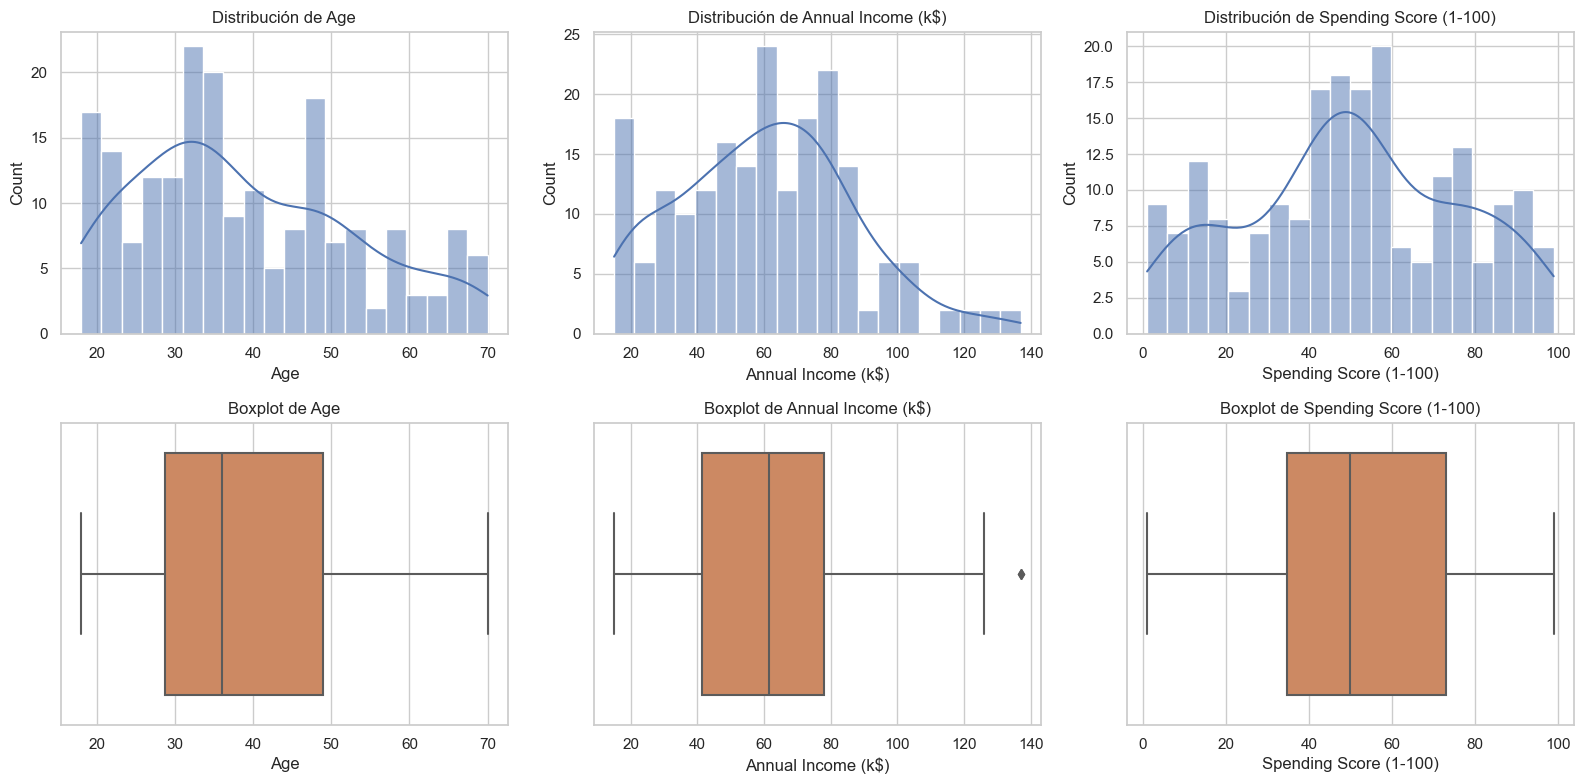

Asimetría (skewness):
Age                       0.486
Annual Income (k$)        0.322
Spending Score (1-100)   -0.047
dtype: float64


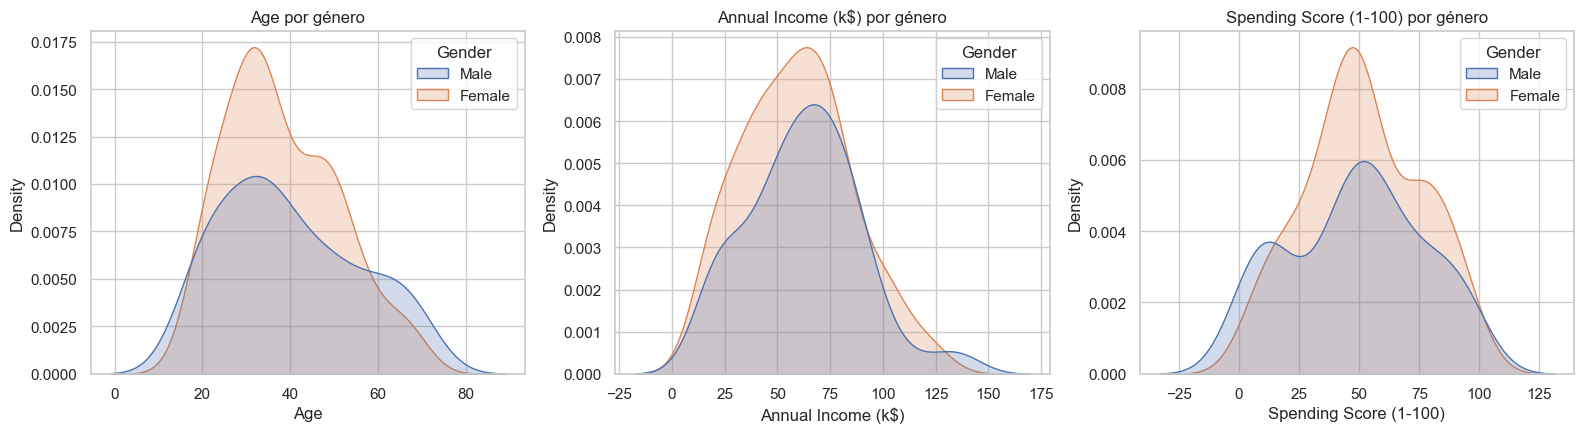

         Age  Annual Income (k$)  Spending Score (1-100)
Gender                                                  
Female  38.1                59.2                    51.5
Male    39.8                62.2                    48.5


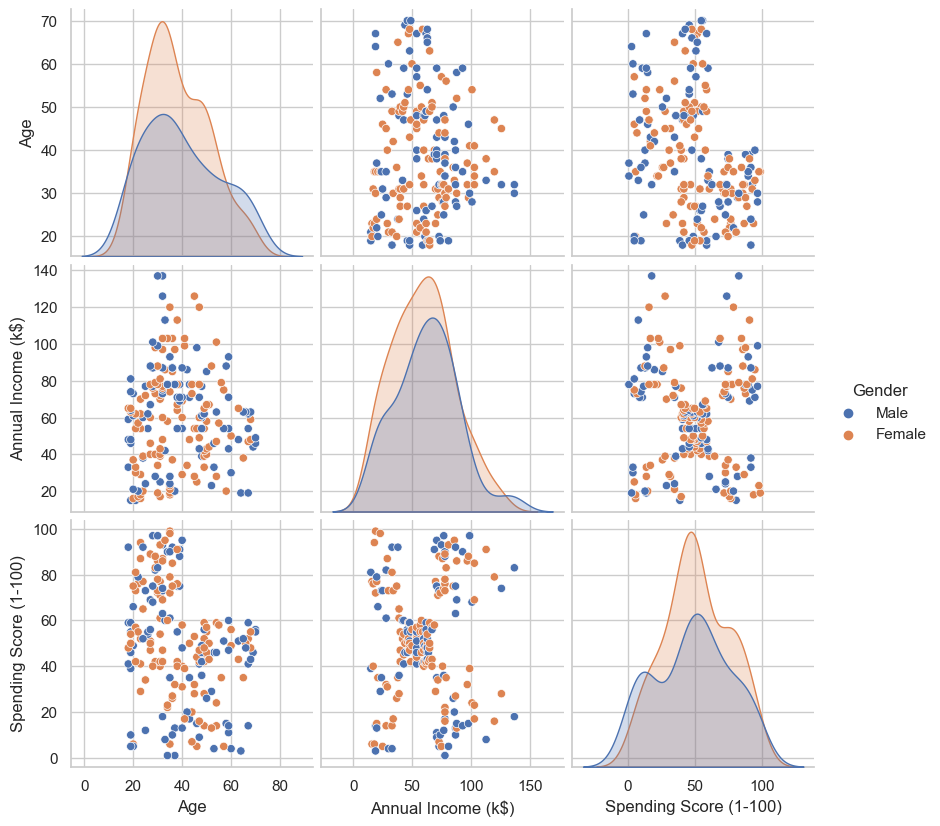

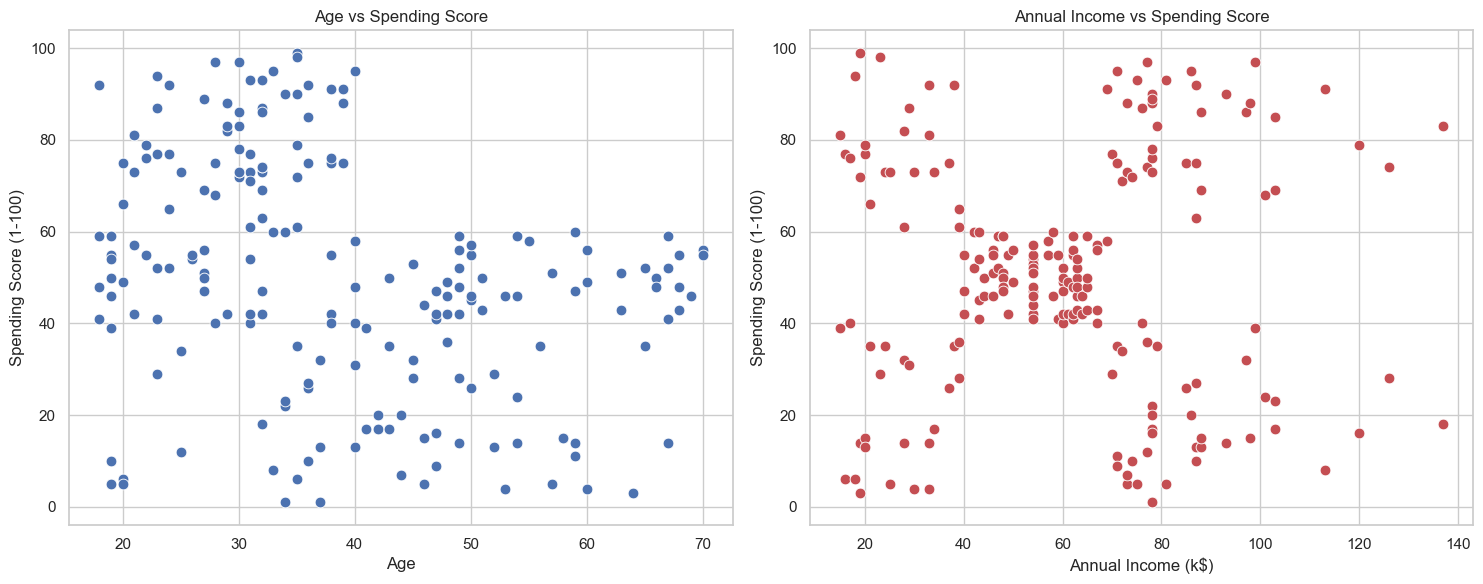

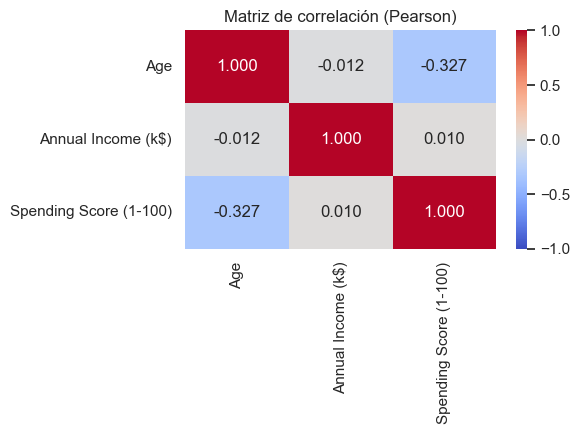

In [9]:
# Clasificación estadística de cada variable
tipos = pd.DataFrame({
    "Tipo pandas": df.dtypes.astype(str),
    "Tipo estadístico": [
        "Identificador (nominal, sin valor analítico)",
        "Categórica nominal binaria",
        "Numérica discreta (años enteros)",
        "Numérica continua (registrada en miles de USD, redondeada)",
        "Numérica ordinal/discreta acotada [1, 100]"
    ]
})
print(tipos)
 
print(df.describe().round(2))
 
print(df["Gender"].value_counts())
print((df["Gender"].value_counts(normalize=True) * 100).round(1))
 
num_cols = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
 
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, bins=20, ax=axes[0, i], color="#4C72B0")
    axes[0, i].set_title(f"Distribución de {col}")
    sns.boxplot(x=df[col], ax=axes[1, i], color="#DD8452")
    axes[1, i].set_title(f"Boxplot de {col}")
plt.tight_layout()
plt.savefig("fig1_distribuciones.png", dpi=150)
plt.show()
 
print("Asimetría (skewness):")
print(df[num_cols].skew().round(3))
 
# Distribución por género
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for i, col in enumerate(num_cols):
    sns.kdeplot(data=df, x=col, hue="Gender", fill=True, ax=axes[i])
    axes[i].set_title(f"{col} por género")
plt.tight_layout()
plt.savefig("fig2_por_genero.png", dpi=150)
plt.show()
print(df.groupby("Gender")[num_cols].mean().round(1))
 
sns.pairplot(df.drop(columns="CustomerID"), hue="Gender", diag_kind="kde", height=2.8)
plt.savefig("fig3_pairplot.png", dpi=150)
plt.show()
 
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(data=df, x="Age", y="Spending Score (1-100)", ax=axes[0], s=60, color="#4C72B0")
axes[0].set_title("Age vs Spending Score")
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)", ax=axes[1], s=60, color="#C44E52")
axes[1].set_title("Annual Income vs Spending Score")
plt.tight_layout()
plt.savefig("fig4_scatters.png", dpi=150)
plt.show()
 
plt.figure(figsize=(6, 4.5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación (Pearson)")
plt.tight_layout()
plt.savefig("fig5_correlacion.png", dpi=150)
plt.show()

### Limpieza de Datos

In [10]:
##Limpieza de datos 
from sklearn.preprocessing import StandardScaler

df_modelo = df.drop(columns=["CustomerID"])
df_modelo = df_modelo.drop(columns=["Gender"])

print("\nANTES del escalado:")
print(df_modelo[num_cols].describe().round(2).loc[["mean", "std", "min", "max"]])

## Se utiliza el stadardScaler
scaler = StandardScaler()                       # z = (x - media) / desviación estándar
X_scaled = scaler.fit_transform(df_modelo[num_cols])
df_scaled = pd.DataFrame(X_scaled, columns=num_cols)

print("\nDESPUÉS del escalado (StandardScaler):")
print(df_scaled.describe().round(3).loc[["mean", "std", "min", "max"]])




ANTES del escalado:
        Age  Annual Income (k$)  Spending Score (1-100)
mean  38.85               60.56                   50.20
std   13.97               26.26                   25.82
min   18.00               15.00                    1.00
max   70.00              137.00                   99.00

DESPUÉS del escalado (StandardScaler):
        Age  Annual Income (k$)  Spending Score (1-100)
mean -0.000              -0.000                  -0.000
std   1.003               1.003                   1.003
min  -1.496              -1.739                  -1.910
max   2.236               2.918                   1.894


### Construcción del dataset

In [ ]:
import numpy as np

features = ["Annual Income (k$)", "Spending Score (1-100)"]

# Matriz final X como arreglo numpy
X = df_scaled[features].to_numpy()

print("Tipo de objeto:", type(X))
print("Dimensiones de X:", X.shape)        # (200, 2)
print("Tipo de dato:", X.dtype)
print("\nPrimeras 5 filas de X:")
print(np.round(X[:5], 3))
print("\nMedia por columna:", np.round(X.mean(axis=0), 3))
print("Desv. estándar por columna:", np.round(X.std(axis=0), 3))

Tipo de objeto: <class 'numpy.ndarray'>
Dimensiones de X: (200, 2)
Tipo de dato: float64

Primeras 5 filas de X:
[[-1.739 -0.435]
 [-1.739  1.196]
 [-1.701 -1.716]
 [-1.701  1.04 ]
 [-1.663 -0.396]]

Media por columna: [-0. -0.]
Desv. estándar por columna: [1. 1.]


### Verificación de Resultados y Selección de K

c:\Users\Diego\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Diego\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Diego\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Diego\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Window

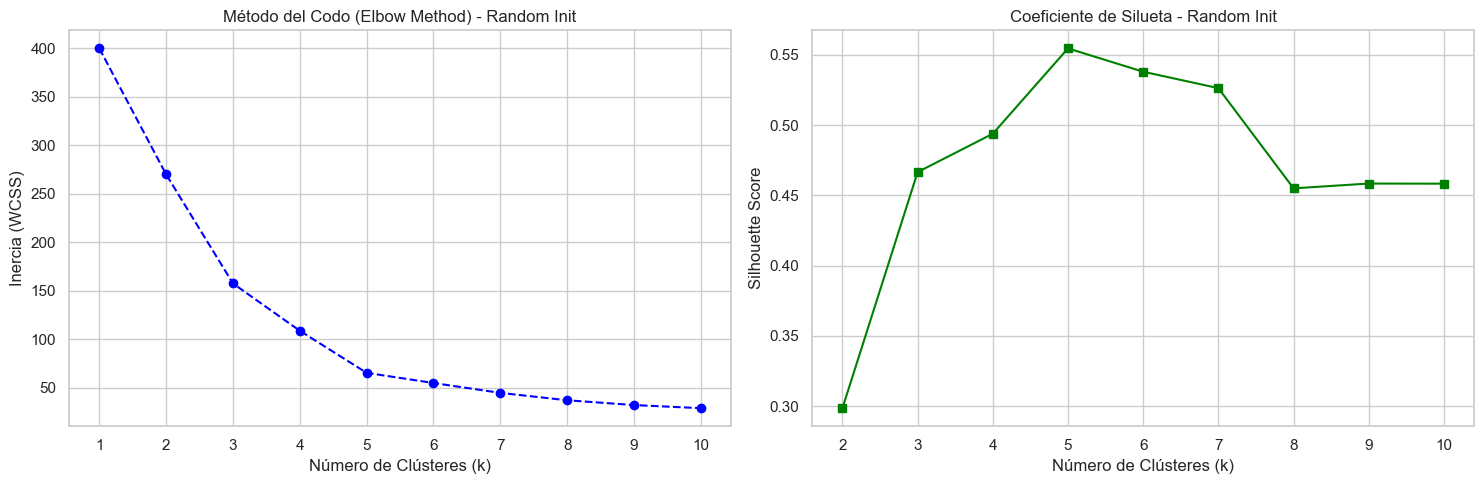

In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

wcss = []
silhouette_scores = []

# Evaluación de k entre 1 y 10
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='random', random_state=42, n_init=10)
    kmeans.fit(X)
    
    # Cálculo de Inercia (WCSS)
    wcss.append(kmeans.inertia_)
    
    # Cálculo del Coeficiente de Silueta (solo para k > 1)
    if k > 1:
        score = silhouette_score(X, kmeans.labels_)
        silhouette_scores.append(score)
    else:
        silhouette_scores.append(0)

# Visualización de métricas
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(K_range, wcss, marker='o', linestyle='--', color='blue')
axes[0].set_title('Método del Codo (Elbow Method) - Random Init')
axes[0].set_xlabel('Número de Clústeres (k)')
axes[0].set_ylabel('Inercia (WCSS)')
axes[0].set_xticks(K_range)

axes[1].plot(range(2, 11), silhouette_scores[1:], marker='s', linestyle='-', color='green')
axes[1].set_title('Coeficiente de Silueta - Random Init')
axes[1].set_xlabel('Número de Clústeres (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(range(2, 11))

plt.tight_layout()
plt.show()

### Depuración y Análisis de Negocio

In [24]:
import pandas as pd
import numpy as np
import time
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Ajuste del modelo aleatorio con k=5 y medición de tiempo
start_time = time.time()
kmeans_random = KMeans(n_clusters=5, init='random', random_state=42, n_init=10)
kmeans_random.fit(X)
tiempo_ejecucion = time.time() - start_time

print(f"Tiempo de convergencia (Random Init): {tiempo_ejecucion:.5f} segundos\n")
print(f"Inercia del modelo (WCSS): {kmeans_random.inertia_:.4f}\n")

# Extraemos los centroides para que el resto de tu código funcione
centroides_escalados = kmeans_random.cluster_centers_

# 2. Reversión de escala (tu código)
# Ajustamos un nuevo scaler SOLO con las 2 variables de interés en su escala original
scaler_final = StandardScaler()
scaler_final.fit(df[["Annual Income (k$)", "Spending Score (1-100)"]])

# Revertimos el escalado de los centroides con este scaler específico
centroides_originales = scaler_final.inverse_transform(centroides_escalados)

# Consolidamos en el DataFrame
df_centroides = pd.DataFrame(
    np.round(centroides_originales, 2), 
    columns=["Annual Income (k$)", "Spending Score (1-100)"]
)
df_centroides.index = [f"Clúster {i}" for i in range(5)]

print("Centroides en escala original:")
print(df_centroides)

c:\Users\Diego\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Tiempo de convergencia (Random Init): 0.41626 segundos

Inercia del modelo (WCSS): 65.5684

Centroides en escala original:
           Annual Income (k$)  Spending Score (1-100)
Clúster 0               26.30                   20.91
Clúster 1               88.20                   17.11
Clúster 2               55.30                   49.52
Clúster 3               25.73                   79.36
Clúster 4               86.54                   82.13


### Comparación de Modelos

In [23]:
import time
from sklearn.cluster import KMeans

start_time_plus = time.time()
# Implementación de la librería con inicialización optimizada[cite: 3]
kmeans_plus = KMeans(n_clusters=5, init='k-means++', random_state=42, n_init=10)
kmeans_plus.fit(X)
time_plus = time.time() - start_time_plus

print("K-Means (++ Init):")
print(f" - Inercia final (WCSS): {kmeans_plus.inertia_:.4f}")
print(f" - Tiempo de convergencia: {time_plus:.5f} segundos")

c:\Users\Diego\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


K-Means (++ Init):
 - Inercia final (WCSS): 65.5684
 - Tiempo de convergencia: 0.47493 segundos
